OVERALL DELIVERY PERFORMANCE ANALYSIS

LOAD AND INSPECT ANALYTICAL DATASET
Source file: C:\Users\hp\Analysis in Global Supply Chain Operations\data\processed\delivery_gap_analysis.csv
Dataset rows: 180,519
Dataset columns: 39
Actual duration column: Days for shipping (real)
Scheduled duration column: Days for shipment (scheduled)
Delivery gap column: Delivery Delay Gap
Classification column: Delivery Classification

VALIDATE DELIVERY PERFORMANCE DATA
Total records: 180,519
Eligible shipment records: 172,765
Cancelled shipments: 7,754
Ineligible records: 0
Valid risk labels: 180,519

CALCULATE OVERALL SHIPMENT COUNTS
Total shipment records: 180,519
Eligible shipment records: 172,765
Delayed shipments: 98,977
On-time shipments: 32,196
Early shipments: 41,592
Cancelled shipments: 7,754
Ineligible shipments: 0

CALCULATE DELIVERY STATUS DISTRIBUTION
  Delivery Status  Record Count  Percentage
    Late delivery         98977   54.829132
 Advance shipping         41592   23.040234
 Shipping 

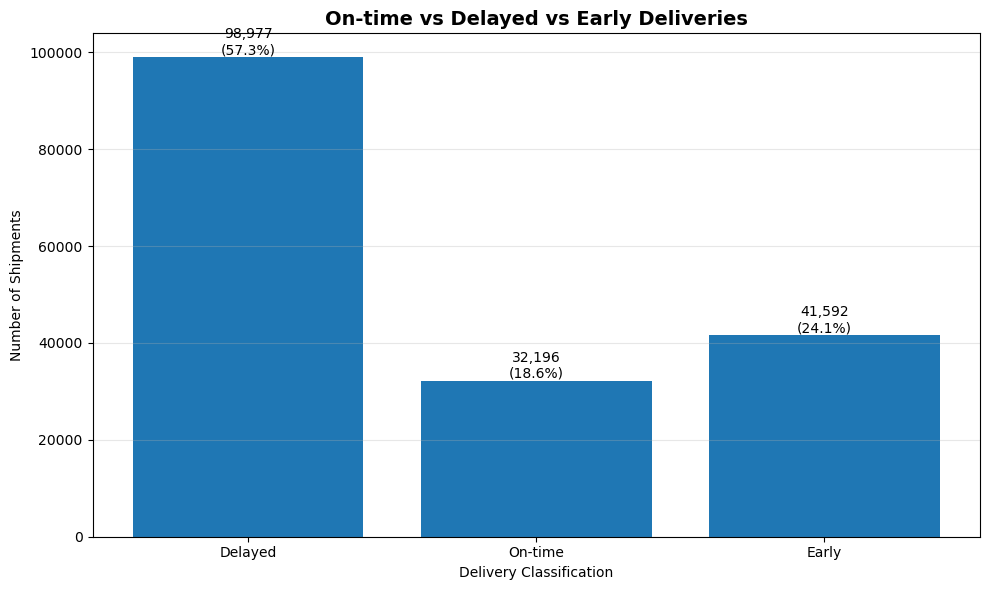

Saved chart: C:\Users\hp\Analysis in Global Supply Chain Operations\outputs\figures\delivery_classification_comparison.png

CREATE DELIVERY STATUS DISTRIBUTION CHART


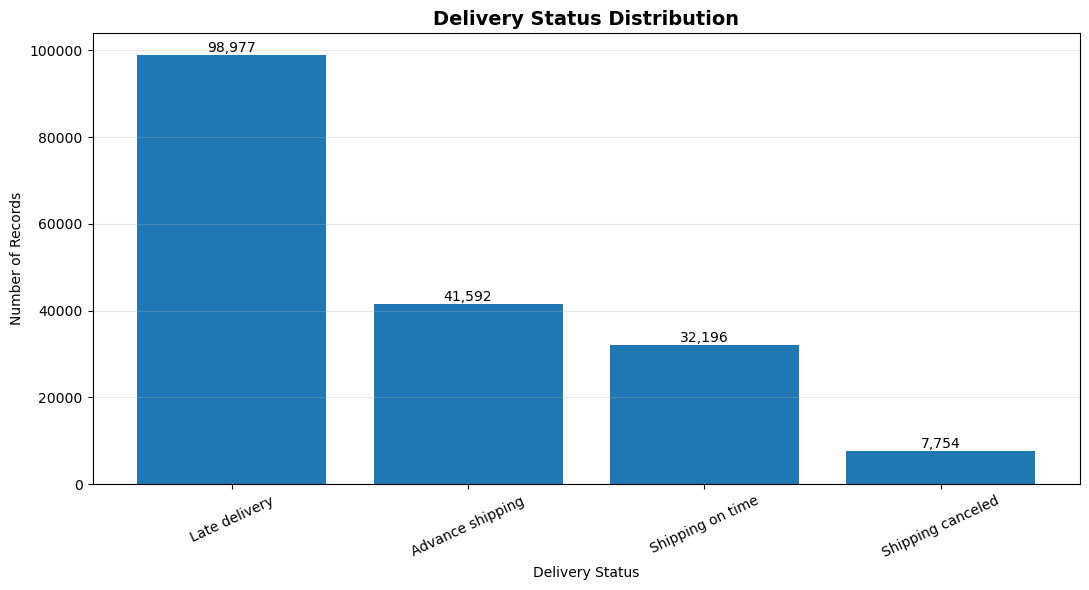

Saved chart: C:\Users\hp\Analysis in Global Supply Chain Operations\outputs\figures\delivery_status_distribution.png

CREATE DELIVERY GAP HISTOGRAM


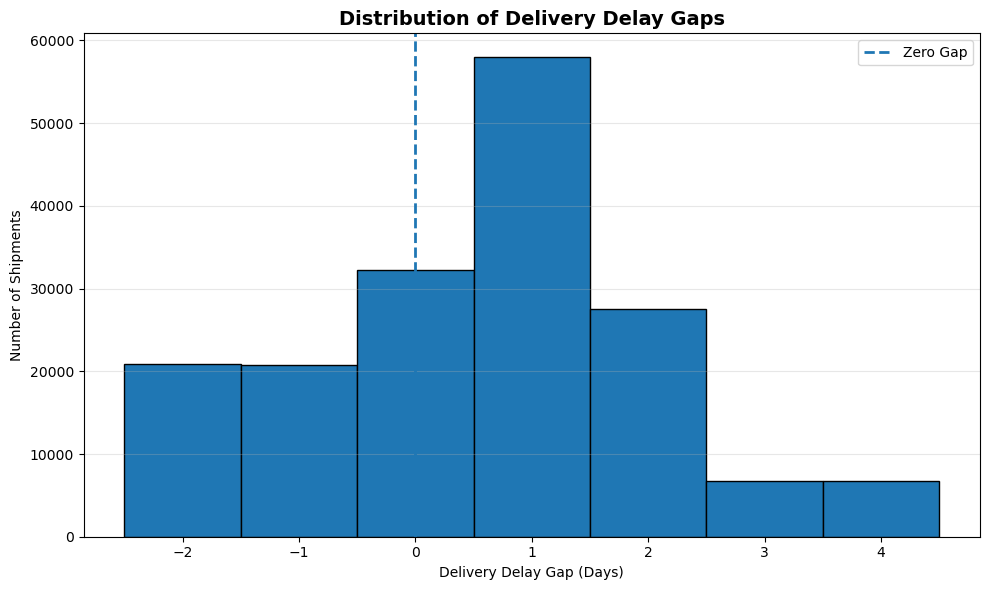

Saved chart: C:\Users\hp\Analysis in Global Supply Chain Operations\outputs\figures\delivery_gap_histogram.png

CREATE ACTUAL VS SCHEDULED DURATION COMPARISON CHART


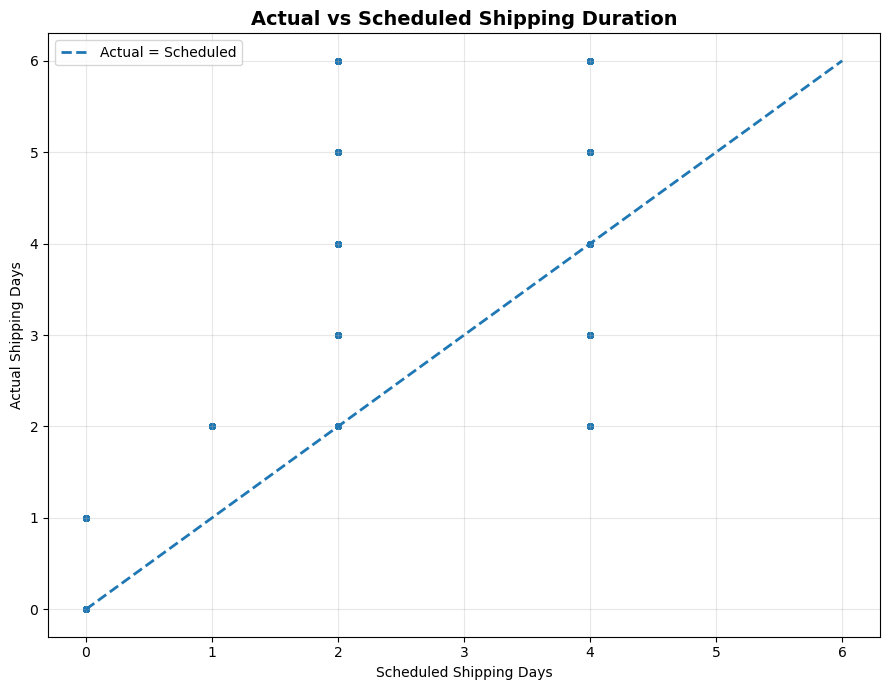

Records used in scatter plot: 15,000
Saved chart: C:\Users\hp\Analysis in Global Supply Chain Operations\outputs\figures\actual_vs_scheduled_duration.png

CREATE LATE DELIVERY RISK DISTRIBUTION CHART


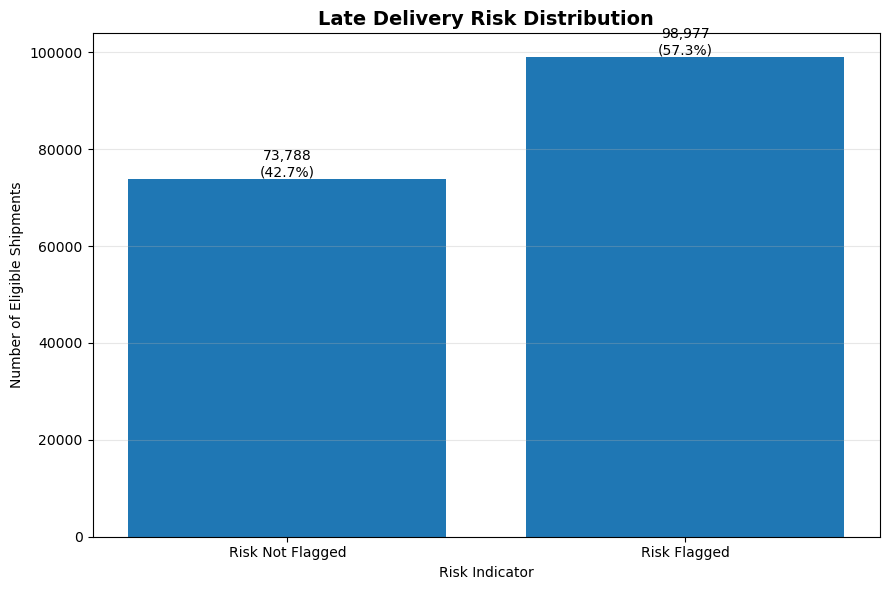

Saved chart: C:\Users\hp\Analysis in Global Supply Chain Operations\outputs\figures\late_delivery_risk_distribution.png

CREATE DELIVERY PERFORMANCE SUMMARY TABLE
   Performance Indicator      Result
  Total Shipment Records 180519.0000
      Eligible Shipments 172765.0000
       Delayed Shipments  98977.0000
       On-time Shipments  32196.0000
         Early Shipments  41592.0000
     Cancelled Shipments   7754.0000
    Ineligible Shipments      0.0000
   On-time Delivery Rate     18.6400
   Delayed Delivery Rate     57.2900
     Early Delivery Rate     24.0700
  Average Delivery Delay      1.6200
   Median Delivery Delay      1.0000
  Maximum Delivery Delay      4.0000
    Minimum Delivery Gap     -2.0000
Late Delivery Risk Ratio      0.5729
     Risk Mismatch Count      0.0000

VALIDATE OVERALL DELIVERY PERFORMANCE RESULTS
                                 Validation Check Actual Value Expected Value Status
                 Total shipment records preserved       180519         18051

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
from datetime import datetime

print("=" * 100)
print("OVERALL DELIVERY PERFORMANCE ANALYSIS")
print("=" * 100)

# ------------------------------------------------------------
# PROJECT PATH CONFIGURATION
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\hp\Analysis in Global Supply Chain Operations"
)

INPUT_FILE = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "delivery_gap_analysis.csv"
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "outputs" / "reports"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"

for directory in [
    PROCESSED_DIR,
    REPORT_DIR,
    TABLE_DIR,
    FIGURE_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

OUTPUT_FILES = {
    "performance_summary": TABLE_DIR / "overall_delivery_performance.csv",
    "delivery_status_distribution": TABLE_DIR / "delivery_status_distribution.csv",
    "classification_summary": TABLE_DIR / "delivery_classification_percentages.csv",
    "risk_distribution": TABLE_DIR / "late_delivery_risk_distribution.csv",
    "risk_comparison": TABLE_DIR / "delivery_risk_comparison.csv",
    "mismatch_report": REPORT_DIR / "overall_delivery_risk_mismatch_report.csv",
    "baseline_performance": TABLE_DIR / "baseline_logistics_performance.csv",
    "kpi_report": TABLE_DIR / "delivery_performance_kpis.csv",
    "validation_report": REPORT_DIR / "overall_delivery_performance_validation.csv",
    "summary_json": REPORT_DIR / "overall_delivery_performance_summary.json"
}

ACTUAL_COL = "Days for shipping (real)"
SCHEDULED_COL = "Days for shipment (scheduled)"
GAP_COL = "Delivery Delay Gap"
CLASS_COL = "Delivery Classification"
STATUS_COL = "Delivery Status"
RISK_COL = "Late_delivery_risk"

# ------------------------------------------------------------
# LOAD AND INSPECT ANALYTICAL DATASET
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("LOAD AND INSPECT ANALYTICAL DATASET")
print("=" * 100)

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"Analytical dataset not found: {INPUT_FILE}"
    )

df = pd.read_csv(INPUT_FILE)

original_record_count = len(df)

required_columns = [
    ACTUAL_COL,
    SCHEDULED_COL,
    GAP_COL,
    CLASS_COL,
    STATUS_COL,
    RISK_COL
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}"
    )

print(f"Source file: {INPUT_FILE}")
print(f"Dataset rows: {len(df):,}")
print(f"Dataset columns: {len(df.columns):,}")
print(f"Actual duration column: {ACTUAL_COL}")
print(f"Scheduled duration column: {SCHEDULED_COL}")
print(f"Delivery gap column: {GAP_COL}")
print(f"Classification column: {CLASS_COL}")

# ------------------------------------------------------------
# VALIDATE DELIVERY PERFORMANCE DATA
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("VALIDATE DELIVERY PERFORMANCE DATA")
print("=" * 100)

for column in [
    ACTUAL_COL,
    SCHEDULED_COL,
    GAP_COL,
    RISK_COL
]:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

df[CLASS_COL] = (
    df[CLASS_COL]
    .astype("string")
    .str.strip()
)

df[STATUS_COL] = (
    df[STATUS_COL]
    .astype("string")
    .str.strip()
)

actual_valid = (
    df[ACTUAL_COL].notna()
    & np.isfinite(df[ACTUAL_COL])
    & (df[ACTUAL_COL] >= 0)
)

scheduled_valid = (
    df[SCHEDULED_COL].notna()
    & np.isfinite(df[SCHEDULED_COL])
    & (df[SCHEDULED_COL] >= 0)
)

gap_valid = (
    df[GAP_COL].notna()
    & np.isfinite(df[GAP_COL])
)

risk_valid = (
    df[RISK_COL].notna()
    & df[RISK_COL].isin([0, 1])
)

eligible_mask = (
    df[CLASS_COL].isin(["Delayed", "On-time", "Early"])
    & actual_valid
    & scheduled_valid
    & gap_valid
)

cancelled_mask = df[CLASS_COL].eq("Cancelled")

ineligible_mask = ~eligible_mask & ~cancelled_mask

eligible_df = df.loc[eligible_mask].copy()

print(f"Total records: {len(df):,}")
print(f"Eligible shipment records: {len(eligible_df):,}")
print(f"Cancelled shipments: {cancelled_mask.sum():,}")
print(f"Ineligible records: {ineligible_mask.sum():,}")
print(f"Valid risk labels: {risk_valid.sum():,}")

if eligible_df.empty:
    raise ValueError(
        "No eligible shipment records available for performance analysis."
    )

# ------------------------------------------------------------
# CALCULATE OVERALL SHIPMENT COUNTS
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("CALCULATE OVERALL SHIPMENT COUNTS")
print("=" * 100)

total_shipments = int(len(df))
eligible_shipments = int(eligible_mask.sum())

delayed_shipments = int(
    (eligible_df[CLASS_COL] == "Delayed").sum()
)

on_time_shipments = int(
    (eligible_df[CLASS_COL] == "On-time").sum()
)

early_shipments = int(
    (eligible_df[CLASS_COL] == "Early").sum()
)

cancelled_shipments = int(cancelled_mask.sum())
ineligible_shipments = int(ineligible_mask.sum())

print(f"Total shipment records: {total_shipments:,}")
print(f"Eligible shipment records: {eligible_shipments:,}")
print(f"Delayed shipments: {delayed_shipments:,}")
print(f"On-time shipments: {on_time_shipments:,}")
print(f"Early shipments: {early_shipments:,}")
print(f"Cancelled shipments: {cancelled_shipments:,}")
print(f"Ineligible shipments: {ineligible_shipments:,}")

# ------------------------------------------------------------
# CALCULATE DELIVERY STATUS DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("CALCULATE DELIVERY STATUS DISTRIBUTION")
print("=" * 100)

delivery_status_distribution = (
    df[STATUS_COL]
    .fillna("Missing")
    .value_counts(dropna=False)
    .rename_axis("Delivery Status")
    .reset_index(name="Record Count")
)

delivery_status_distribution["Percentage"] = (
    delivery_status_distribution["Record Count"]
    / max(total_shipments, 1)
    * 100
)

delivery_status_distribution.to_csv(
    OUTPUT_FILES["delivery_status_distribution"],
    index=False
)

print(delivery_status_distribution.to_string(index=False))

# ------------------------------------------------------------
# CALCULATE DELIVERY CLASSIFICATION PERCENTAGES
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("CALCULATE DELIVERY CLASSIFICATION PERCENTAGES")
print("=" * 100)

classification_order = [
    "Delayed",
    "On-time",
    "Early"
]

classification_counts = {
    category: int(
        (eligible_df[CLASS_COL] == category).sum()
    )
    for category in classification_order
}

classification_summary = pd.DataFrame({
    "Delivery Classification": classification_order,
    "Shipment Count": [
        classification_counts[category]
        for category in classification_order
    ]
})

classification_summary["Percentage"] = (
    classification_summary["Shipment Count"]
    / max(eligible_shipments, 1)
    * 100
)

classification_summary.to_csv(
    OUTPUT_FILES["classification_summary"],
    index=False
)

on_time_delivery_percentage = (
    on_time_shipments / eligible_shipments * 100
)

delayed_delivery_percentage = (
    delayed_shipments / eligible_shipments * 100
)

early_delivery_percentage = (
    early_shipments / eligible_shipments * 100
)

print(classification_summary.to_string(index=False))

print(
    f"\nOn-time delivery percentage: "
    f"{on_time_delivery_percentage:.2f}%"
)

print(
    f"Delayed delivery percentage: "
    f"{delayed_delivery_percentage:.2f}%"
)

print(
    f"Early delivery percentage: "
    f"{early_delivery_percentage:.2f}%"
)

# ------------------------------------------------------------
# CALCULATE DELIVERY DELAY STATISTICS
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("CALCULATE DELIVERY DELAY STATISTICS")
print("=" * 100)

# Delay statistics are calculated from delayed shipments only.
# Negative and zero gaps are not included in average delay.

delayed_gaps = eligible_df.loc[
    eligible_df[CLASS_COL] == "Delayed",
    GAP_COL
]

all_eligible_gaps = eligible_df[GAP_COL]

if len(delayed_gaps) > 0:
    average_delivery_delay = float(
        delayed_gaps.mean()
    )

    median_delivery_delay = float(
        delayed_gaps.median()
    )

    maximum_delivery_delay = float(
        delayed_gaps.max()
    )
else:
    average_delivery_delay = 0.0
    median_delivery_delay = 0.0
    maximum_delivery_delay = 0.0

minimum_delivery_gap = float(
    all_eligible_gaps.min()
)

maximum_delivery_gap = float(
    all_eligible_gaps.max()
)

average_delivery_gap = float(
    all_eligible_gaps.mean()
)

median_delivery_gap = float(
    all_eligible_gaps.median()
)

print(
    f"Average delivery delay among delayed shipments: "
    f"{average_delivery_delay:.2f} days"
)

print(
    f"Median delivery delay among delayed shipments: "
    f"{median_delivery_delay:.2f} days"
)

print(
    f"Maximum delivery delay: "
    f"{maximum_delivery_delay:.2f} days"
)

print(
    f"Minimum delivery gap: "
    f"{minimum_delivery_gap:.2f} days"
)

print(
    f"Maximum delivery gap: "
    f"{maximum_delivery_gap:.2f} days"
)

print(
    f"Average delivery gap across eligible shipments: "
    f"{average_delivery_gap:.2f} days"
)

print(
    f"Median delivery gap across eligible shipments: "
    f"{median_delivery_gap:.2f} days"
)

# ------------------------------------------------------------
# CALCULATE LATE DELIVERY RISK DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("CALCULATE LATE DELIVERY RISK DISTRIBUTION")
print("=" * 100)

risk_analysis_df = df.loc[
    eligible_mask & risk_valid
].copy()

risk_distribution = (
    risk_analysis_df[RISK_COL]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("Late Delivery Risk")
    .reset_index(name="Record Count")
)

risk_distribution["Risk Description"] = (
    risk_distribution["Late Delivery Risk"]
    .map({
        0: "Risk Not Flagged",
        1: "Risk Flagged"
    })
)

risk_distribution["Percentage"] = (
    risk_distribution["Record Count"]
    / max(len(risk_analysis_df), 1)
    * 100
)

risk_distribution.to_csv(
    OUTPUT_FILES["risk_distribution"],
    index=False
)

risk_flagged_count = int(
    (risk_analysis_df[RISK_COL] == 1).sum()
)

risk_not_flagged_count = int(
    (risk_analysis_df[RISK_COL] == 0).sum()
)

late_delivery_risk_ratio = (
    risk_flagged_count
    / max(len(risk_analysis_df), 1)
)

late_delivery_risk_percentage = (
    late_delivery_risk_ratio * 100
)

print(risk_distribution.to_string(index=False))

print(
    f"\nRisk flagged shipments: {risk_flagged_count:,}"
)

print(
    f"Risk not flagged shipments: {risk_not_flagged_count:,}"
)

print(
    f"Late delivery risk ratio: "
    f"{late_delivery_risk_ratio:.4f}"
)

print(
    f"Late delivery risk percentage: "
    f"{late_delivery_risk_percentage:.2f}%"
)

# ------------------------------------------------------------
# COMPARE RISK INDICATOR WITH CALCULATED DELIVERY CLASSIFICATION
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("COMPARE RISK INDICATOR WITH CALCULATED DELIVERY CLASSIFICATION")
print("=" * 100)

risk_comparison_df = risk_analysis_df.copy()

risk_comparison_df["Calculated Risk Expectation"] = np.where(
    risk_comparison_df[CLASS_COL] == "Delayed",
    1,
    0
)

risk_comparison_df["Risk Comparison Result"] = np.where(
    risk_comparison_df[RISK_COL]
    == risk_comparison_df["Calculated Risk Expectation"],
    "Consistent",
    "Mismatch"
)

risk_mismatch_mask = (
    risk_comparison_df["Risk Comparison Result"]
    == "Mismatch"
)

risk_mismatch_records = risk_comparison_df.loc[
    risk_mismatch_mask
].copy()

risk_mismatch_records.to_csv(
    OUTPUT_FILES["mismatch_report"],
    index=False
)

risk_comparison_summary = (
    risk_comparison_df["Risk Comparison Result"]
    .value_counts()
    .rename_axis("Risk Comparison Result")
    .reset_index(name="Record Count")
)

risk_comparison_summary["Percentage"] = (
    risk_comparison_summary["Record Count"]
    / max(len(risk_comparison_df), 1)
    * 100
)

risk_comparison_summary.to_csv(
    OUTPUT_FILES["risk_comparison"],
    index=False
)

risk_mismatch_count = int(
    risk_mismatch_mask.sum()
)

risk_consistent_count = int(
    len(risk_comparison_df) - risk_mismatch_count
)

risk_mismatch_percentage = (
    risk_mismatch_count
    / max(len(risk_comparison_df), 1)
    * 100
)

print(risk_comparison_summary.to_string(index=False))

print(f"\nConsistent risk records: {risk_consistent_count:,}")
print(f"Risk mismatches: {risk_mismatch_count:,}")
print(f"Risk mismatch percentage: {risk_mismatch_percentage:.2f}%")

# ------------------------------------------------------------
# IDENTIFY BASELINE LOGISTICS PERFORMANCE
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("IDENTIFY BASELINE LOGISTICS PERFORMANCE")
print("=" * 100)

# Baseline performance represents the observed historical
# delivery outcomes. It is descriptive, not a predictive model.

baseline_summary = pd.DataFrame({
    "Baseline Metric": [
        "Total Shipment Records",
        "Eligible Shipment Records",
        "Delayed Shipments",
        "On-time Shipments",
        "Early Shipments",
        "Cancelled Shipments",
        "Ineligible Shipments",
        "On-time Delivery Rate",
        "Delayed Delivery Rate",
        "Early Delivery Rate",
        "Average Delay Among Delayed Shipments",
        "Median Delay Among Delayed Shipments",
        "Late Delivery Risk Ratio",
        "Risk Mismatch Percentage"
    ],
    "Value": [
        total_shipments,
        eligible_shipments,
        delayed_shipments,
        on_time_shipments,
        early_shipments,
        cancelled_shipments,
        ineligible_shipments,
        on_time_delivery_percentage,
        delayed_delivery_percentage,
        early_delivery_percentage,
        average_delivery_delay,
        median_delivery_delay,
        late_delivery_risk_ratio,
        risk_mismatch_percentage
    ],
    "Unit": [
        "Records",
        "Records",
        "Records",
        "Records",
        "Records",
        "Records",
        "Records",
        "%",
        "%",
        "%",
        "Days",
        "Days",
        "Ratio",
        "%"
    ]
})

baseline_summary.to_csv(
    OUTPUT_FILES["baseline_performance"],
    index=False
)

print(baseline_summary.to_string(index=False))

# ------------------------------------------------------------
# GENERATE DELIVERY PERFORMANCE KPI TABLE
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("GENERATE DELIVERY PERFORMANCE KPI TABLE")
print("=" * 100)

kpi_results = pd.DataFrame({
    "KPI": [
        "Total Shipment Records",
        "Eligible Shipment Records",
        "On-Time Delivery Percentage",
        "Delayed Delivery Percentage",
        "Early Delivery Percentage",
        "Average Delivery Delay",
        "Median Delivery Delay",
        "Maximum Delivery Delay",
        "Minimum Delivery Gap",
        "Late Delivery Risk Ratio",
        "Late Delivery Risk Percentage",
        "Risk Mismatch Count",
        "Risk Mismatch Percentage",
        "Cancelled Shipment Percentage"
    ],
    "Value": [
        total_shipments,
        eligible_shipments,
        on_time_delivery_percentage,
        delayed_delivery_percentage,
        early_delivery_percentage,
        average_delivery_delay,
        median_delivery_delay,
        maximum_delivery_delay,
        minimum_delivery_gap,
        late_delivery_risk_ratio,
        late_delivery_risk_percentage,
        risk_mismatch_count,
        risk_mismatch_percentage,
        cancelled_shipments / max(total_shipments, 1) * 100
    ],
    "Unit": [
        "Records",
        "Records",
        "%",
        "%",
        "%",
        "Days",
        "Days",
        "Days",
        "Days",
        "Ratio",
        "%",
        "Records",
        "%",
        "%"
    ]
})

kpi_results.to_csv(
    OUTPUT_FILES["kpi_report"],
    index=False
)

print(kpi_results.to_string(index=False))

# ------------------------------------------------------------
# CREATE DELIVERY CLASSIFICATION COMPARISON CHART
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("CREATE DELIVERY CLASSIFICATION COMPARISON CHART")
print("=" * 100)

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    classification_summary["Delivery Classification"],
    classification_summary["Shipment Count"]
)

ax.set_title(
    "On-time vs Delayed vs Early Deliveries",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Delivery Classification")
ax.set_ylabel("Number of Shipments")

for index, row in classification_summary.iterrows():
    ax.text(
        index,
        row["Shipment Count"],
        f"{int(row['Shipment Count']):,}\n({row['Percentage']:.1f}%)",
        ha="center",
        va="bottom"
    )

ax.grid(axis="y", alpha=0.3)
plt.tight_layout()

classification_chart = (
    FIGURE_DIR / "delivery_classification_comparison.png"
)

fig.savefig(
    classification_chart,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print(f"Saved chart: {classification_chart}")

# ------------------------------------------------------------
# CREATE DELIVERY STATUS DISTRIBUTION CHART
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("CREATE DELIVERY STATUS DISTRIBUTION CHART")
print("=" * 100)

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    delivery_status_distribution["Delivery Status"],
    delivery_status_distribution["Record Count"]
)

ax.set_title(
    "Delivery Status Distribution",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Delivery Status")
ax.set_ylabel("Number of Records")

ax.tick_params(
    axis="x",
    rotation=25
)

for index, row in delivery_status_distribution.iterrows():
    ax.text(
        index,
        row["Record Count"],
        f"{int(row['Record Count']):,}",
        ha="center",
        va="bottom"
    )

ax.grid(axis="y", alpha=0.3)
plt.tight_layout()

status_chart = (
    FIGURE_DIR / "delivery_status_distribution.png"
)

fig.savefig(
    status_chart,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print(f"Saved chart: {status_chart}")

# ------------------------------------------------------------
# CREATE DELIVERY GAP HISTOGRAM
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("CREATE DELIVERY GAP HISTOGRAM")
print("=" * 100)

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    all_eligible_gaps,
    bins=np.arange(
        all_eligible_gaps.min() - 0.5,
        all_eligible_gaps.max() + 1.5,
        1
    ),
    edgecolor="black"
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=2,
    label="Zero Gap"
)

ax.set_title(
    "Distribution of Delivery Delay Gaps",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Delivery Delay Gap (Days)")
ax.set_ylabel("Number of Shipments")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

gap_histogram = (
    FIGURE_DIR / "delivery_gap_histogram.png"
)

fig.savefig(
    gap_histogram,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print(f"Saved chart: {gap_histogram}")

# ------------------------------------------------------------
# CREATE ACTUAL VS SCHEDULED DURATION COMPARISON CHART
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("CREATE ACTUAL VS SCHEDULED DURATION COMPARISON CHART")
print("=" * 100)

# A deterministic sample keeps the scatter plot readable
# while preserving the complete dataset for calculations.

plot_sample = eligible_df[
    [ACTUAL_COL, SCHEDULED_COL]
].copy()

if len(plot_sample) > 15000:
    plot_sample = plot_sample.sample(
        n=15000,
        random_state=42
    )

fig, ax = plt.subplots(figsize=(9, 7))

ax.scatter(
    plot_sample[SCHEDULED_COL],
    plot_sample[ACTUAL_COL],
    alpha=0.25,
    s=12
)

comparison_min = min(
    plot_sample[SCHEDULED_COL].min(),
    plot_sample[ACTUAL_COL].min()
)

comparison_max = max(
    plot_sample[SCHEDULED_COL].max(),
    plot_sample[ACTUAL_COL].max()
)

ax.plot(
    [comparison_min, comparison_max],
    [comparison_min, comparison_max],
    linestyle="--",
    linewidth=2,
    label="Actual = Scheduled"
)

ax.set_title(
    "Actual vs Scheduled Shipping Duration",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Scheduled Shipping Days")
ax.set_ylabel("Actual Shipping Days")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

duration_chart = (
    FIGURE_DIR / "actual_vs_scheduled_duration.png"
)

fig.savefig(
    duration_chart,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print(f"Records used in scatter plot: {len(plot_sample):,}")
print(f"Saved chart: {duration_chart}")

# ------------------------------------------------------------
# CREATE LATE DELIVERY RISK DISTRIBUTION CHART
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("CREATE LATE DELIVERY RISK DISTRIBUTION CHART")
print("=" * 100)

fig, ax = plt.subplots(figsize=(9, 6))

risk_labels = [
    "Risk Not Flagged",
    "Risk Flagged"
]

risk_values = [
    risk_not_flagged_count,
    risk_flagged_count
]

risk_percentages = [
    risk_not_flagged_count / max(len(risk_analysis_df), 1) * 100,
    risk_flagged_count / max(len(risk_analysis_df), 1) * 100
]

ax.bar(
    risk_labels,
    risk_values
)

ax.set_title(
    "Late Delivery Risk Distribution",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Risk Indicator")
ax.set_ylabel("Number of Eligible Shipments")

for index, value in enumerate(risk_values):
    ax.text(
        index,
        value,
        f"{value:,}\n({risk_percentages[index]:.1f}%)",
        ha="center",
        va="bottom"
    )

ax.grid(axis="y", alpha=0.3)
plt.tight_layout()

risk_chart = (
    FIGURE_DIR / "late_delivery_risk_distribution.png"
)

fig.savefig(
    risk_chart,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print(f"Saved chart: {risk_chart}")

# ------------------------------------------------------------
# CREATE DELIVERY PERFORMANCE SUMMARY TABLE
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("CREATE DELIVERY PERFORMANCE SUMMARY TABLE")
print("=" * 100)

performance_summary = pd.DataFrame({
    "Performance Indicator": [
        "Total Shipment Records",
        "Eligible Shipments",
        "Delayed Shipments",
        "On-time Shipments",
        "Early Shipments",
        "Cancelled Shipments",
        "Ineligible Shipments",
        "On-time Delivery Rate",
        "Delayed Delivery Rate",
        "Early Delivery Rate",
        "Average Delivery Delay",
        "Median Delivery Delay",
        "Maximum Delivery Delay",
        "Minimum Delivery Gap",
        "Late Delivery Risk Ratio",
        "Risk Mismatch Count"
    ],
    "Result": [
        total_shipments,
        eligible_shipments,
        delayed_shipments,
        on_time_shipments,
        early_shipments,
        cancelled_shipments,
        ineligible_shipments,
        round(on_time_delivery_percentage, 2),
        round(delayed_delivery_percentage, 2),
        round(early_delivery_percentage, 2),
        round(average_delivery_delay, 2),
        round(median_delivery_delay, 2),
        round(maximum_delivery_delay, 2),
        round(minimum_delivery_gap, 2),
        round(late_delivery_risk_ratio, 4),
        risk_mismatch_count
    ]
})

performance_summary.to_csv(
    OUTPUT_FILES["performance_summary"],
    index=False
)

print(performance_summary.to_string(index=False))

# ------------------------------------------------------------
# VALIDATE OVERALL DELIVERY PERFORMANCE RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("VALIDATE OVERALL DELIVERY PERFORMANCE RESULTS")
print("=" * 100)

validation_results = []

def add_validation(
    check_name,
    actual_value,
    expected_value,
    passed
):
    validation_results.append({
        "Validation Check": check_name,
        "Actual Value": str(actual_value),
        "Expected Value": str(expected_value),
        "Status": "PASS" if passed else "FAIL"
    })

# Verify shipment population reconciliation.

add_validation(
    "Total shipment records preserved",
    total_shipments,
    original_record_count,
    total_shipments == original_record_count
)

add_validation(
    "Eligible shipment classification totals reconcile",
    delayed_shipments + on_time_shipments + early_shipments,
    eligible_shipments,
    (
        delayed_shipments
        + on_time_shipments
        + early_shipments
    ) == eligible_shipments
)

add_validation(
    "All shipment categories reconcile",
    (
        eligible_shipments
        + cancelled_shipments
        + ineligible_shipments
    ),
    total_shipments,
    (
        eligible_shipments
        + cancelled_shipments
        + ineligible_shipments
    ) == total_shipments
)

add_validation(
    "Delivery classification percentages reconcile",
    round(
        on_time_delivery_percentage
        + delayed_delivery_percentage
        + early_delivery_percentage,
        6
    ),
    100.0,
    np.isclose(
        on_time_delivery_percentage
        + delayed_delivery_percentage
        + early_delivery_percentage,
        100.0
    )
)

add_validation(
    "Delivery status distribution reconciles",
    int(delivery_status_distribution["Record Count"].sum()),
    total_shipments,
    int(delivery_status_distribution["Record Count"].sum()) == total_shipments
)

add_validation(
    "Risk distribution reconciles",
    int(risk_distribution["Record Count"].sum()),
    len(risk_analysis_df),
    int(risk_distribution["Record Count"].sum()) == len(risk_analysis_df)
)

add_validation(
    "Risk comparison population reconciles",
    len(risk_comparison_df),
    len(risk_analysis_df),
    len(risk_comparison_df) == len(risk_analysis_df)
)

add_validation(
    "Risk mismatch records reconcile",
    risk_mismatch_count + risk_consistent_count,
    len(risk_comparison_df),
    (
        risk_mismatch_count + risk_consistent_count
    ) == len(risk_comparison_df)
)

add_validation(
    "On-time delivery percentage within valid range",
    round(on_time_delivery_percentage, 4),
    "0 to 100",
    0 <= on_time_delivery_percentage <= 100
)

add_validation(
    "Delayed delivery percentage within valid range",
    round(delayed_delivery_percentage, 4),
    "0 to 100",
    0 <= delayed_delivery_percentage <= 100
)

add_validation(
    "Early delivery percentage within valid range",
    round(early_delivery_percentage, 4),
    "0 to 100",
    0 <= early_delivery_percentage <= 100
)

add_validation(
    "Delivery delay statistics are valid",
    "Valid" if (
        np.isfinite(average_delivery_delay)
        and np.isfinite(median_delivery_delay)
        and np.isfinite(maximum_delivery_delay)
        and np.isfinite(minimum_delivery_gap)
    ) else "Invalid",
    "Valid",
    (
        np.isfinite(average_delivery_delay)
        and np.isfinite(median_delivery_delay)
        and np.isfinite(maximum_delivery_delay)
        and np.isfinite(minimum_delivery_gap)
    )
)

validation_report = pd.DataFrame(
    validation_results
)

validation_report.to_csv(
    OUTPUT_FILES["validation_report"],
    index=False
)

print(validation_report.to_string(index=False))

# ------------------------------------------------------------
# SAVE OVERALL DELIVERY PERFORMANCE SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("SAVE OVERALL DELIVERY PERFORMANCE SUMMARY")
print("=" * 100)

summary = {
    "analysis_name": "Overall Delivery Performance Analysis",
    "generated_at": datetime.now().isoformat(timespec="seconds"),
    "source_file": str(INPUT_FILE),
    "total_shipment_records": int(total_shipments),
    "eligible_shipment_records": int(eligible_shipments),
    "delayed_shipments": int(delayed_shipments),
    "on_time_shipments": int(on_time_shipments),
    "early_shipments": int(early_shipments),
    "cancelled_shipments": int(cancelled_shipments),
    "ineligible_shipments": int(ineligible_shipments),
    "on_time_delivery_percentage": float(on_time_delivery_percentage),
    "delayed_delivery_percentage": float(delayed_delivery_percentage),
    "early_delivery_percentage": float(early_delivery_percentage),
    "average_delivery_delay_days": float(average_delivery_delay),
    "median_delivery_delay_days": float(median_delivery_delay),
    "maximum_delivery_delay_days": float(maximum_delivery_delay),
    "minimum_delivery_gap_days": float(minimum_delivery_gap),
    "average_delivery_gap_days": float(average_delivery_gap),
    "median_delivery_gap_days": float(median_delivery_gap),
    "risk_flagged_shipments": int(risk_flagged_count),
    "risk_not_flagged_shipments": int(risk_not_flagged_count),
    "late_delivery_risk_ratio": float(late_delivery_risk_ratio),
    "late_delivery_risk_percentage": float(late_delivery_risk_percentage),
    "risk_mismatch_count": int(risk_mismatch_count),
    "risk_mismatch_percentage": float(risk_mismatch_percentage),
    "baseline_performance_type": "Observed historical performance",
    "validation_checks_passed": int(
        (validation_report["Status"] == "PASS").sum()
    ),
    "validation_checks_failed": int(
        (validation_report["Status"] == "FAIL").sum()
    ),
    "validation_passed": bool(
        (validation_report["Status"] == "PASS").all()
    )
}

with open(
    OUTPUT_FILES["summary_json"],
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        summary,
        file,
        indent=4,
        ensure_ascii=False
    )

print(f"Summary saved: {OUTPUT_FILES['summary_json']}")

# ------------------------------------------------------------
# VERIFY ALL EXPECTED OUTPUT FILES
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("VERIFY ALL EXPECTED OUTPUT FILES")
print("=" * 100)

expected_files = list(
    OUTPUT_FILES.values()
) + [
    FIGURE_DIR / "delivery_classification_comparison.png",
    FIGURE_DIR / "delivery_status_distribution.png",
    FIGURE_DIR / "delivery_gap_histogram.png",
    FIGURE_DIR / "actual_vs_scheduled_duration.png",
    FIGURE_DIR / "late_delivery_risk_distribution.png"
]

file_results = []

for file_path in expected_files:
    file_results.append({
        "Output File": str(
            file_path.relative_to(PROJECT_ROOT)
        ),
        "Status": "PASS" if file_path.exists() else "FAIL"
    })

file_report = pd.DataFrame(file_results)

print(file_report.to_string(index=False))

all_files_saved = (
    file_report["Status"] == "PASS"
).all()

# ------------------------------------------------------------
# FINAL OVERALL DELIVERY PERFORMANCE STATUS
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("FINAL OVERALL DELIVERY PERFORMANCE STATUS")
print("=" * 100)

validation_passed = (
    validation_report["Status"] == "PASS"
).all()

print(f"Total shipment records: {total_shipments:,}")
print(f"Eligible shipment records: {eligible_shipments:,}")
print(f"On-time delivery rate: {on_time_delivery_percentage:.2f}%")
print(f"Delayed delivery rate: {delayed_delivery_percentage:.2f}%")
print(f"Early delivery rate: {early_delivery_percentage:.2f}%")
print(f"Average delivery delay: {average_delivery_delay:.2f} days")
print(f"Late delivery risk ratio: {late_delivery_risk_ratio:.4f}")
print(f"Risk mismatches: {risk_mismatch_count:,}")

print(
    f"Validation checks: "
    f"{(validation_report['Status'] == 'PASS').sum()} PASS / "
    f"{(validation_report['Status'] == 'FAIL').sum()} FAIL"
)

print(
    f"Output file verification: "
    f"{'PASS' if all_files_saved else 'FAIL'}"
)

if validation_passed and all_files_saved:
    print("\nOVERALL DELIVERY PERFORMANCE ANALYSIS COMPLETED SUCCESSFULLY")
    print("ALL VALIDATION CHECKS PASSED")
else:
    print("\nOVERALL DELIVERY PERFORMANCE ANALYSIS REQUIRES ATTENTION")

    if not validation_passed:
        print("\nFailed validation checks:")
        print(
            validation_report.loc[
                validation_report["Status"] == "FAIL"
            ].to_string(index=False)
        )

    if not all_files_saved:
        print("\nMissing output files:")
        print(
            file_report.loc[
                file_report["Status"] == "FAIL"
            ].to_string(index=False)
        )